# 03 · Exploratory data analysis: how does the meat change under red, green and blue light?

**Purpose.** Before any model, look at how each photo measurement changes over time in every
session and under each light, and which light carries the most consistent signal.

**Inputs.** `data/processed/frame_stats.parquet` (`foodlens eda-stats`, one row per usable
photo) and the tables / figures written by `foodlens eda` (`reports/tables/eda_*.csv`,
`feature_signal_ranking.csv`, `reports/figures/F5-F8*`).

**Outputs.** None by default (it reads the stage outputs). Set `RECOMPUTE = True` to rerun
`foodlens eda` from here (~30 s).

**Run time.** About 10 s.

**Words used.** *ROI* = the well-lit meat area measured in every photo of a session (same
pixels for R, G and B). *Glints* = tiny bright specular reflections of the wet surface
(moisture), **not bacteria**. *Spearman rho* = how steadily a value rises (+1) or falls (-1)
with time. *Session* = one piece filmed for 2-6 h.

In [1]:
import matplotlib

matplotlib.use("Agg")
import pandas as pd  # noqa: E402
from IPython.display import Image, display  # noqa: E402

from foodlens.config import load_config  # noqa: E402
from foodlens.eda.run import frame_stats_path, run_eda  # noqa: E402

RECOMPUTE = False
cfg = load_config()
tables = cfg.path("reports_dir") / "tables"
figures = cfg.path("reports_dir") / "figures"
HAVE_DATA = frame_stats_path(cfg).is_file() and (tables / "eda_trends.csv").is_file()
if RECOMPUTE and frame_stats_path(cfg).is_file():
    print(run_eda(cfg))
if HAVE_DATA:
    stats = pd.read_parquet(frame_stats_path(cfg))
    print(f"{len(stats)} usable photos, {stats['session_id'].nunique()} sessions")
    print(stats.groupby(["session_id", "light"]).size().unstack())
else:
    print("Missing inputs: run `uv run foodlens eda-stats && uv run foodlens eda` first.")


def show(name: str, width: int = 1100) -> None:
    """Display a saved figure, downscaled to ``width`` px so the notebook stays small (the full
    resolution file is in reports/figures)."""
    from io import BytesIO

    from PIL import Image as PILImage

    f = figures / name
    if not f.is_file():
        print(f"missing figure {f.name}")
        return
    with PILImage.open(f) as im:
        im.thumbnail((width, 4 * width))
        buf = BytesIO()
        im.convert("RGB").save(buf, "PNG", optimize=True)
    display(Image(data=buf.getvalue()))


def table(name: str) -> pd.DataFrame:
    """Read a saved table (empty if missing)."""
    f = tables / name
    return pd.read_csv(f) if f.is_file() else pd.DataFrame()

919 usable photos, 5 sessions
light       BLUE  GREEN  RED
session_id                  
exp1_D1A      19     44   44
exp1_D1B      39     39   40
exp2_D2A      56     56   57
exp2_D2B      60     60   61
exp2_D3A     114    115  115


## 1. Which pixels are measured? (open question 6)
Yellow = the lit ROI used for all features. Cyan = the whole meat including its shadowed side.
The shadowed side is measured separately (`shd_*` columns) so we can see whether it adds
anything. It is very dim (often 4-18 grey levels out of 255), so its values are noisy.

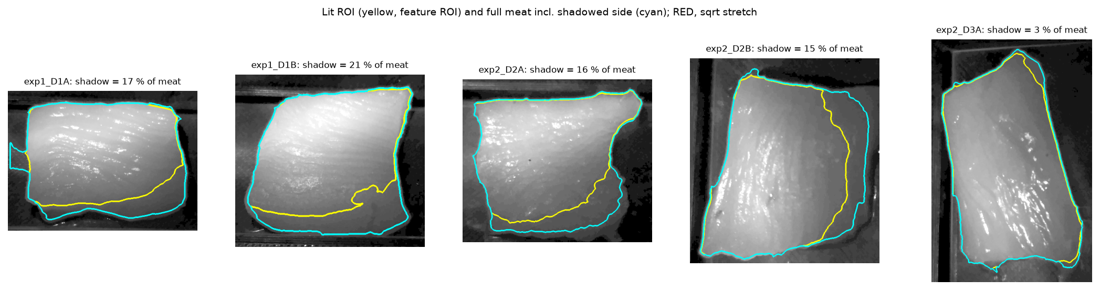

,session_id,lit_px,shadow_px,shadow_frac_of_meat,full_mask_path
0,exp1_D1A,97222,20324,0.172903,data/interim/eda/76aeee4e17/zones/exp1_D1A.png
1,exp1_D1B,85987,22227,0.205399,data/interim/eda/76aeee4e17/zones/exp1_D1B.png
2,exp2_D2A,125887,24488,0.162846,data/interim/eda/76aeee4e17/zones/exp2_D2A.png
3,exp2_D2B,155328,28325,0.154231,data/interim/eda/76aeee4e17/zones/exp2_D2B.png
4,exp2_D3A,186692,6726,0.034774,data/interim/eda/76aeee4e17/zones/exp2_D3A.png


In [2]:
show("qa_zones.png")
display(table("eda_zones.csv"))

## 2. Start, middle and end of each session (F6)
The three photos of one light share **one** brightness stretch, so if the middle or end looks
darker, the meat really is darker. The last panel is end minus start: blue = darker now.

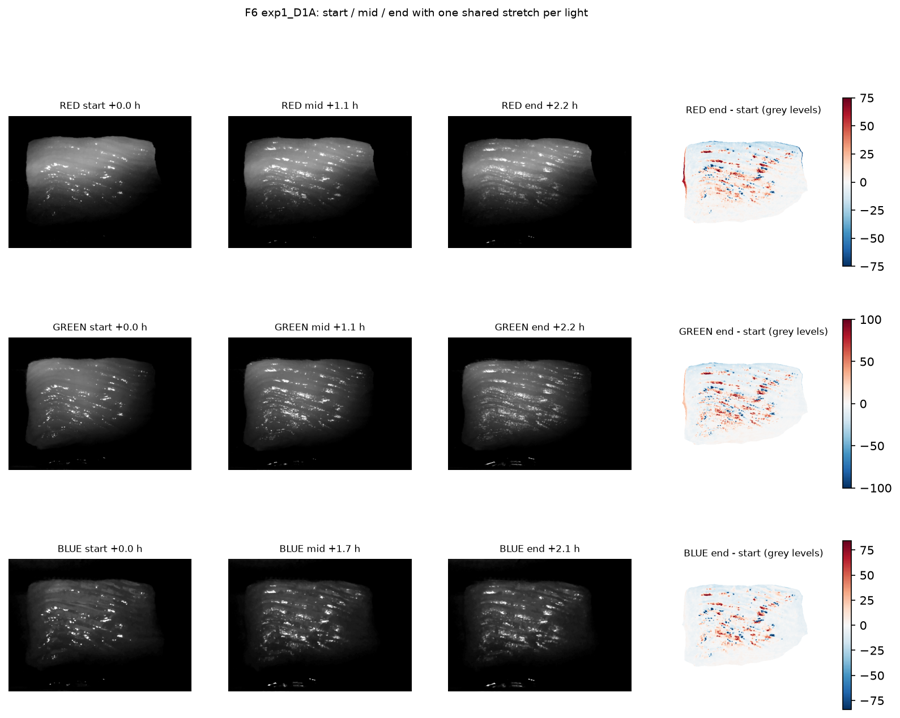

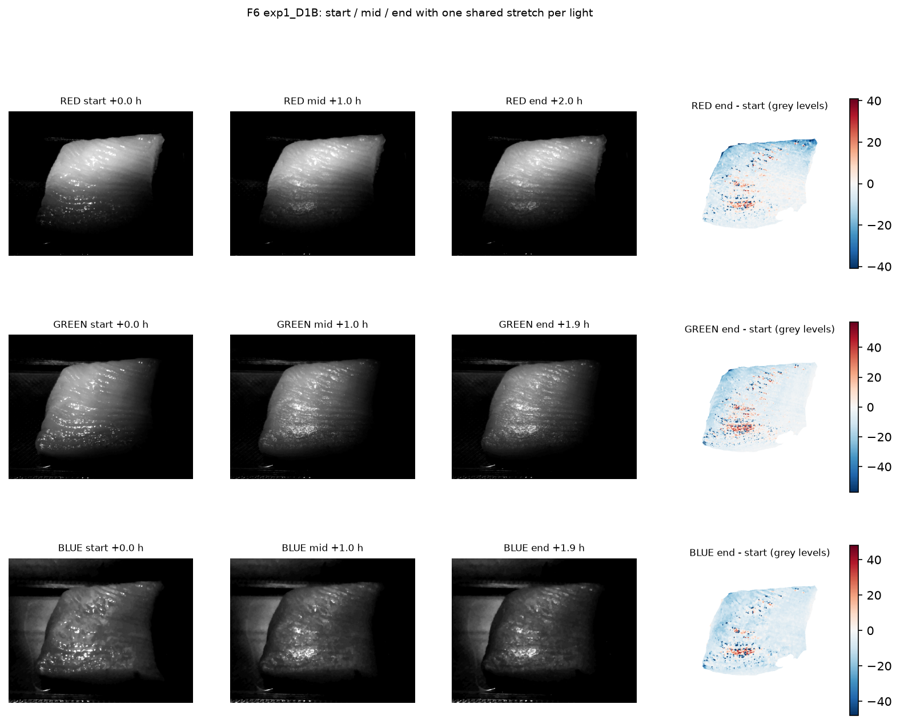

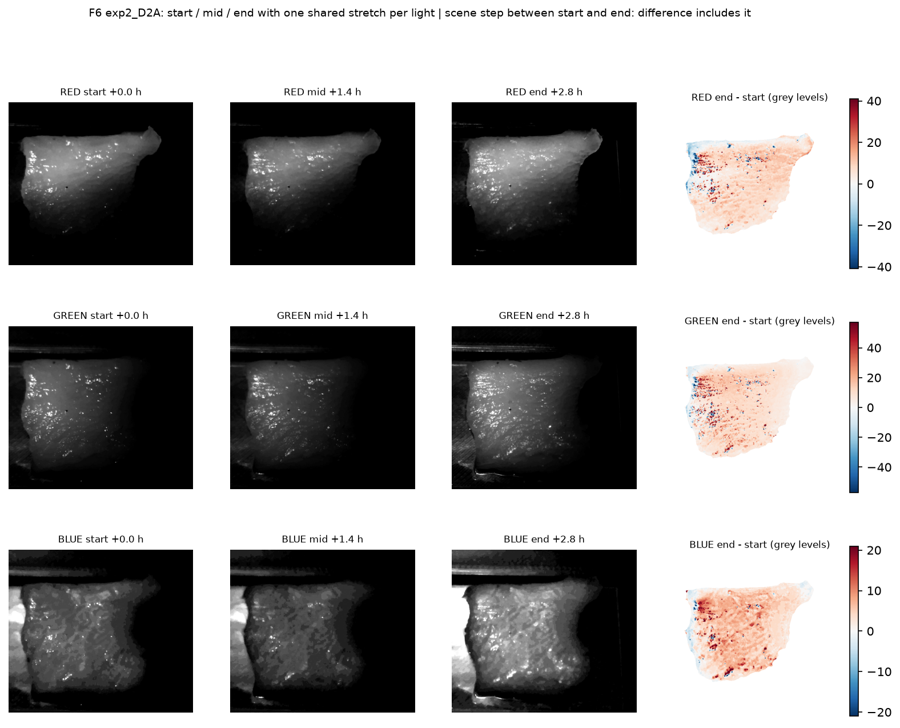

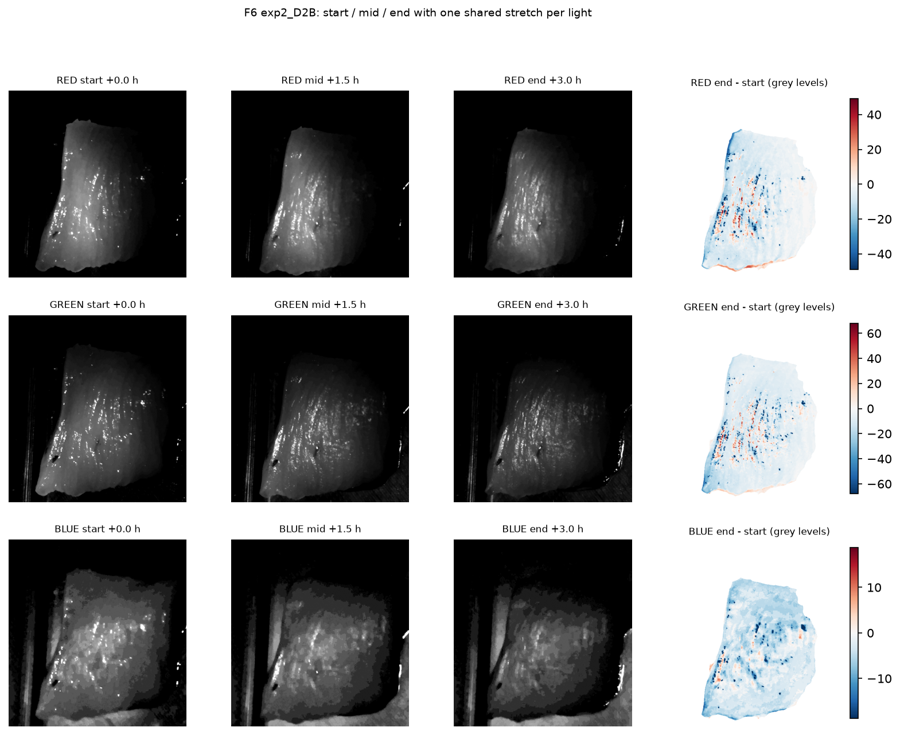

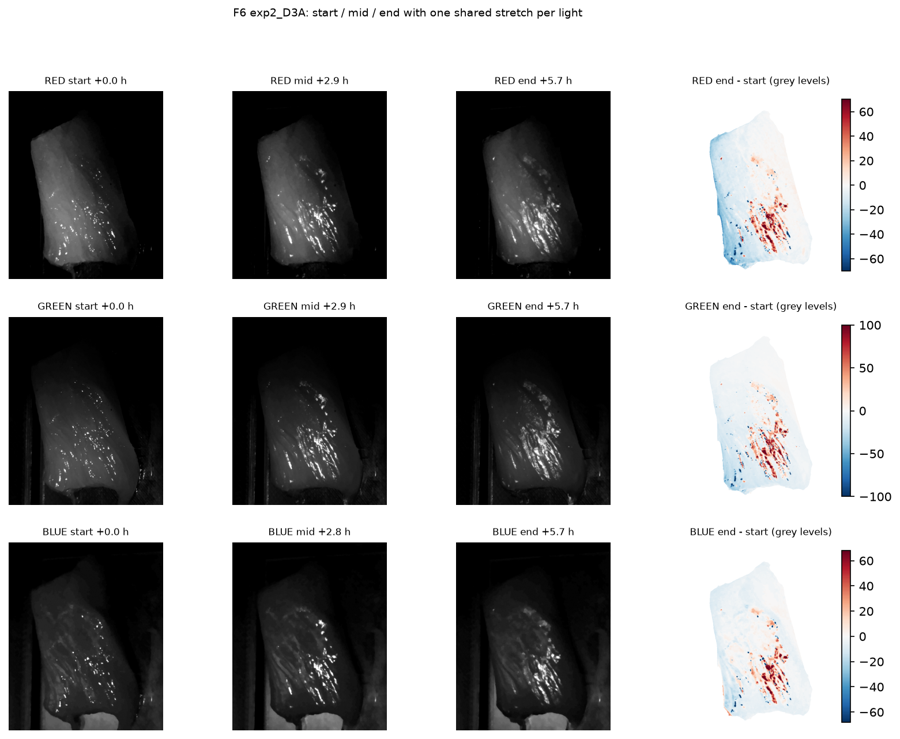

,session_id,light,roi_median_pct_change,glint_count_pct_change,rglint_count_pct_change,glcm_contrast_pct_change,step_between
0,exp1_D1A,BLUE,-6.5,36.1,47.1,4.4,False
1,exp1_D1A,GREEN,-3.2,93.6,87.4,29.5,False
2,exp1_D1A,RED,1.4,56.2,-34.3,-3.4,False
3,exp1_D1B,BLUE,-25.0,-77.2,-51.8,-43.4,False
4,exp1_D1B,GREEN,-15.7,-7.6,6.5,-2.8,False
5,exp1_D1B,RED,-7.4,-65.3,-80.8,-45.0,False
6,exp2_D2A,BLUE,38.5,-48.1,4.5,-18.7,True
7,exp2_D2A,GREEN,40.0,31.7,10.4,-4.8,True
8,exp2_D2A,RED,9.1,11.8,-39.4,11.8,True
9,exp2_D2B,BLUE,-28.6,-100.0,-78.8,-10.7,False


In [3]:
for sid in sorted(stats["session_id"].unique()) if HAVE_DATA else []:
    show(f"F6_start_mid_end_{sid}.png", 900)
cols = ["session_id", "light", "roi_median_pct_change", "glint_count_pct_change"]
cols += ["rglint_count_pct_change", "glcm_contrast_pct_change", "step_between"]
display(table("eda_start_mid_end.csv")[cols].round(1))

## 3. Time series (F5)
Dots are single photos, the line is a rolling median. In `exp2_D2A` the camera's colour
balance jumped at about 1.9 h (dashed line); brightness values are corrected for that jump,
glint values are not (treat D2A glints after the jump with care).
The pooled figure puts all sessions on one scale: every series starts at 1.0.

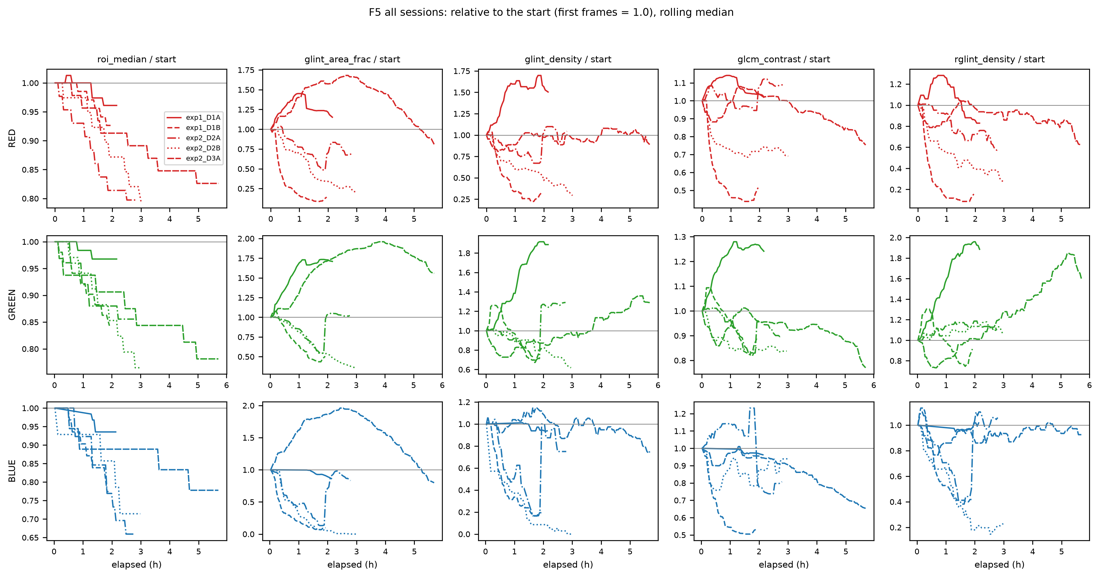

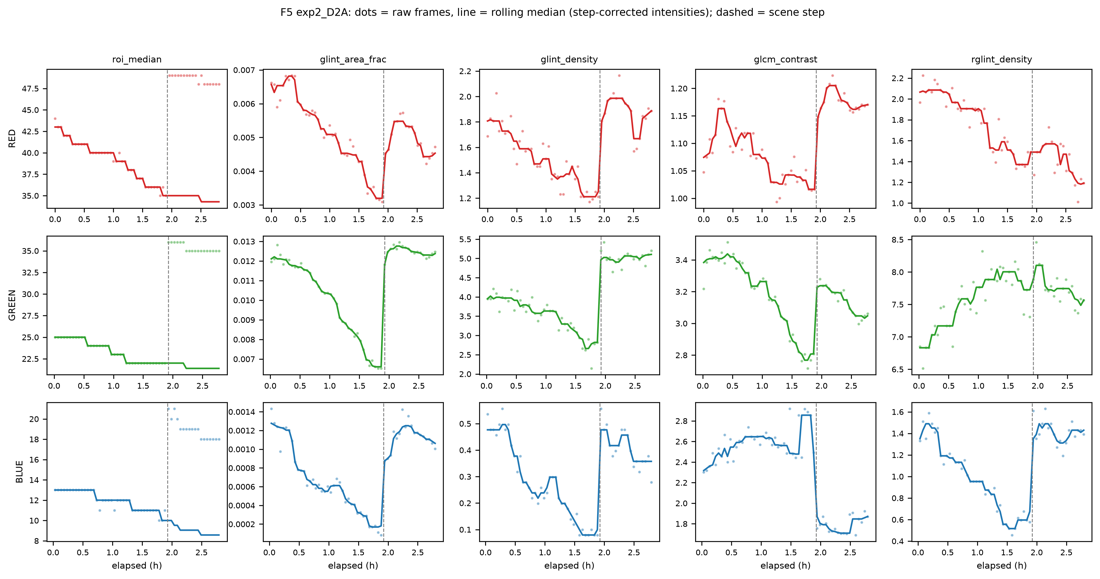

In [4]:
show("F5_relative_all_sessions.png")
show("F5_timeseries_exp2_D2A.png")

### Trend statistics
Per session x light x feature: Spearman rho, its p-value and the Theil-Sen slope (a robust
straight-line slope) in % of the start value per hour. Photos minutes apart are not
independent, so single-session p-values are optimistic; the pooled model below and the
agreement across sessions (section 5) are the honest summaries.

In [5]:
tr = table("eda_trends.csv")
key = ["roi_mean", "roi_mean_rel_ref", "ref_mean", "rglint_density", "glint_density"]
view = tr[(tr["variant"] == "step_corrected") & tr["feature"].isin(key)]
display(view.pivot_table(index=["feature", "light"], columns="session_id", values="rho").round(2))

session_id              exp1_D1A  exp1_D1B  exp2_D2A  exp2_D2B  exp2_D3A
feature          light                                                  
glint_density    BLUE      -0.42     -0.97     -0.12     -0.97     -0.55
                 GREEN      0.98     -0.87      0.38     -0.93      0.92
                 RED        0.62     -0.88      0.18     -0.96      0.42
ref_mean         BLUE      -0.03     -0.84      0.48      0.76      0.91
                 GREEN      0.62      0.92      0.98      0.87      0.34
                 RED        0.40      0.42      0.48      0.76      0.23
rglint_density   BLUE       0.21     -0.92      0.12     -0.92      0.50
                 GREEN      0.96     -0.80      0.47      0.57      0.96
                 RED       -0.56     -0.88     -0.88     -0.96     -0.34
roi_mean         BLUE      -0.88     -1.00     -0.98     -0.98     -0.97
                 GREEN     -0.97     -1.00     -1.00     -1.00     -0.98
                 RED       -0.90     -0.99     -0.97     -0.98     -0.93
roi_mean_rel_ref BLUE      -0.97     -1.00     -1.00     -1.00     -0.97
                 GREEN     -0.82     -1.00     -1.00     -1.00     -0.96
                 RED       -0.57     -0.99     -1.00     -0.98     -0.90

### Pooled mixed model: does it change the same way in every piece?
`value ~ hours` with a separate starting level per session. On the "relative to start" scale
the slope reads as "fraction of the starting value lost (-) or gained (+) per hour".

In [6]:
mm = table("eda_mixed_models.csv")
display(mm[mm["scale"] == "relative to start"].drop(columns=["scale"]).round(4))

,light,feature,n_obs,n_sessions,slope_h,se,ci_lo,ci_hi,p,converged,warning
15,BLUE,roi_median,288,5,-0.0538,0.0027,-0.0591,-0.0486,0.0000,True,The MLE may be on the boundary of the paramete...
16,BLUE,glint_area_frac,288,5,-0.1071,0.0143,-0.1350,-0.0791,0.0000,True,NaN
17,BLUE,glint_density,288,5,-0.0692,0.0096,-0.0881,-0.0504,0.0000,True,NaN
18,BLUE,glcm_contrast,288,5,-0.0600,0.0048,-0.0693,-0.0506,0.0000,True,NaN
19,BLUE,rglint_density,288,5,-0.0243,0.0097,-0.0433,-0.0052,0.0125,True,NaN
20,GREEN,roi_median,314,5,-0.0429,0.0012,-0.0453,-0.0405,0.0000,True,The MLE may be on the boundary of the paramete...
21,GREEN,glint_area_frac,314,5,0.0682,0.0110,0.0466,0.0898,0.0000,True,NaN
22,GREEN,glint_density,314,5,0.0845,0.0089,0.0672,0.1019,0.0000,True,NaN
23,GREEN,glcm_contrast,314,5,-0.0197,0.0029,-0.0253,-0.0141,0.0000,True,NaN
24,GREEN,rglint_density,314,5,0.1631,0.0077,0.1479,0.1782,0.0000,True,NaN


### Control: is it the meat or the lamp?
If the LEDs dimmed while warming up, everything in the box would get darker. `ref_mean` is the
brightness of the lit tray / holder / walls (not meat). It stays flat or slightly rises while
the meat darkens, so the darkening belongs to the meat. `roi_mean_rel_ref` (meat / surroundings)
cancels lamp and camera gain changes.

In [7]:
display(
    view[view["feature"].isin(["ref_mean", "roi_mean"])]
    .pivot_table(index=["feature", "light"], columns="session_id", values="slope_pct_h")
    .round(1)
)

session_id      exp1_D1A  exp1_D1B  exp2_D2A  exp2_D2B  exp2_D3A
feature  light                                                  
ref_mean BLUE       -0.1      -1.5       7.5      21.1       0.9
         GREEN       2.4       2.2       3.4      26.3       0.1
         RED         1.5       0.7       4.4      21.8       0.3
roi_mean BLUE       -2.6     -10.5      -8.5      -9.0      -0.9
         GREEN      -2.3      -5.0      -5.9      -8.2      -2.3
         RED        -1.8      -3.3      -5.4      -5.6      -2.0

## 4. Glint dynamics (F7)
Glints in consecutive photos of the same light are matched: born, died, merged, split or
persisted. "Evaporation" = fewer and smaller glints; "film breaking" = more and smaller;
"merging" = fewer and bigger. Two glint rules are compared: `abs` (fixed brightness floor 40,
the P2 rule) and `rel` (at least 1.75 x the surrounding meat, the same under every light).

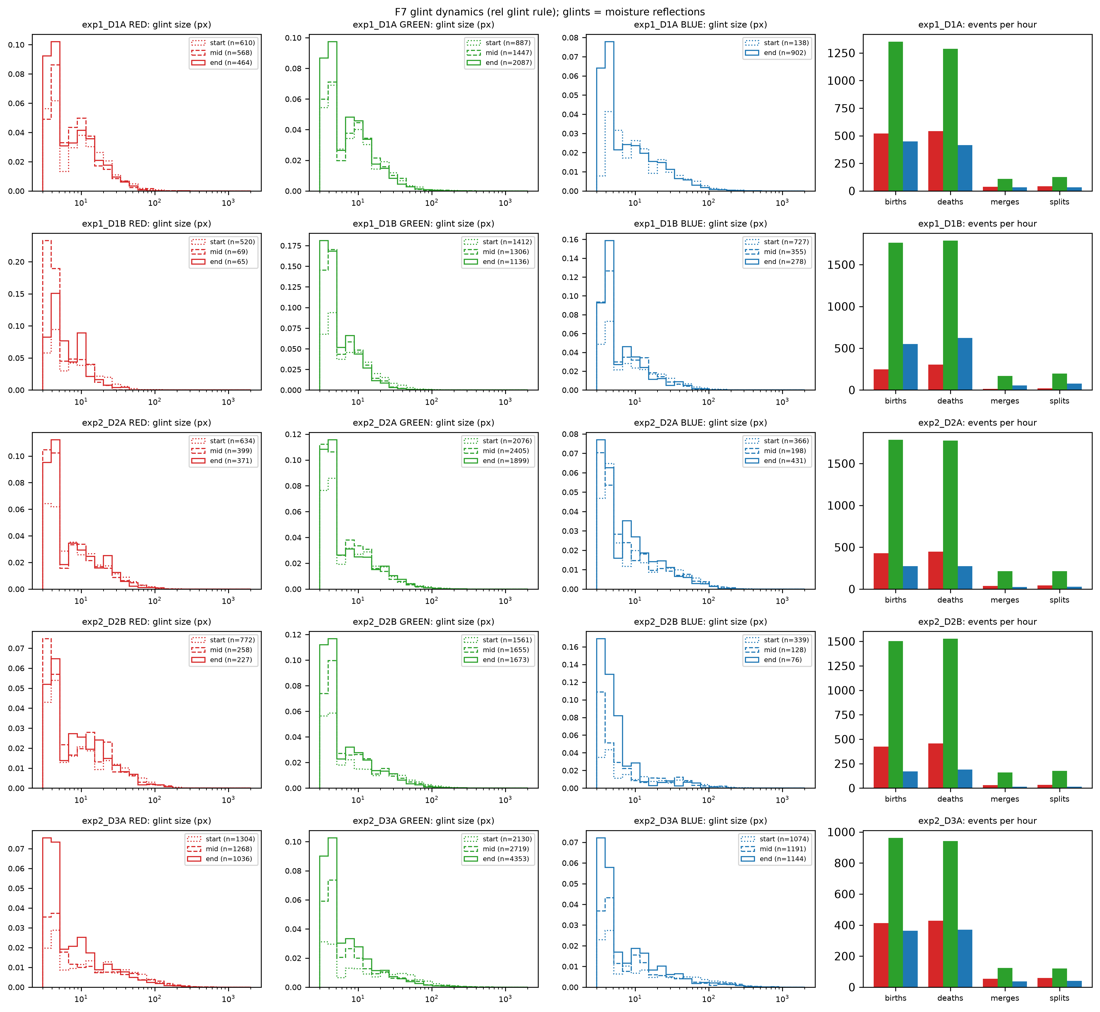

variant                                     abs                            rel
session_id light                                                              
exp1_D1A   BLUE                  no clear trend           smaller (count flat)
           GREEN  film breaking (more, smaller)  film breaking (more, smaller)
           RED    film breaking (more, smaller)   evaporation (fewer, smaller)
exp1_D1B   BLUE    evaporation (fewer, smaller)   evaporation (fewer, smaller)
           GREEN   evaporation (fewer, smaller)   evaporation (fewer, smaller)
           RED     evaporation (fewer, smaller)   evaporation (fewer, smaller)
exp2_D2A   BLUE                  no clear trend           smaller (count flat)
           GREEN  film breaking (more, smaller)  film breaking (more, smaller)
           RED             smaller (count flat)   evaporation (fewer, smaller)
exp2_D2B   BLUE    evaporation (fewer, smaller)   evaporation (fewer, smaller)
           GREEN   evaporation (fewer, smaller)  film breaking (more, smaller)
           RED     evaporation (fewer, smaller)   evaporation (fewer, smaller)
exp2_D3A   BLUE    evaporation (fewer, smaller)  film breaking (more, smaller)
           GREEN  film breaking (more, smaller)  film breaking (more, smaller)
           RED    film breaking (more, smaller)   evaporation (fewer, smaller)

In [8]:
show("F7_glint_dynamics_rel.png")
dyn = table("eda_glint_dynamics.csv")
display(
    dyn.pivot_table(
        index=["session_id", "light"], columns="variant", values="pattern", aggfunc="first"
    )
)

## 5. Which light carries the most information? (F8)
For each feature and light: the mean rho over sessions and how many of the 5 sessions agree on
the direction. A feature is **promising** only if at least 4 of 5 sessions agree.
`TRIPLET` = ratios between the red, green and blue photos of one 3-minute cycle.

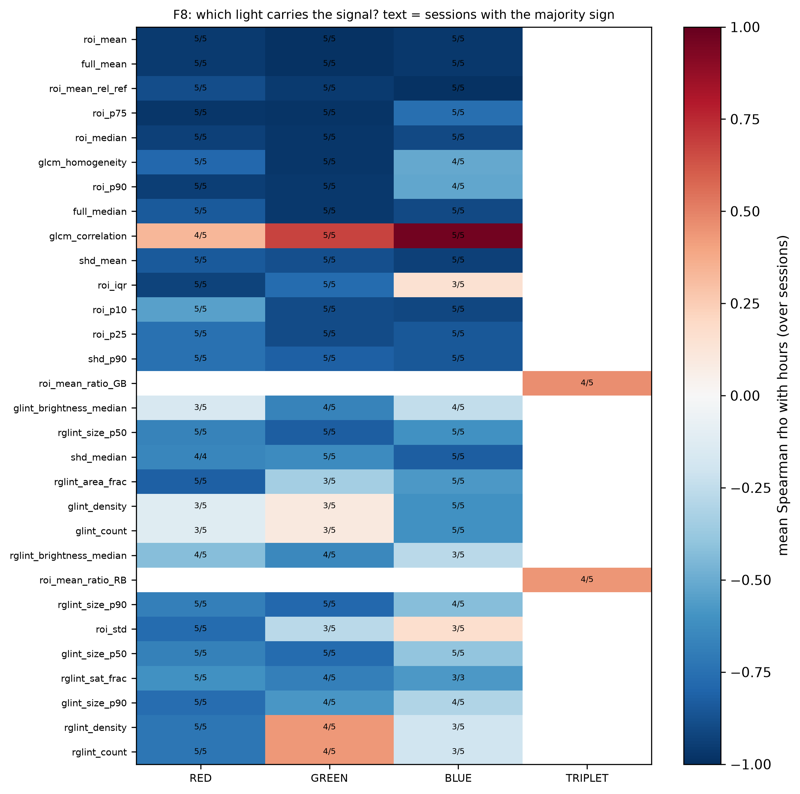

,light,n_features,n_promising,n_all_sessions_significant,top5_mean_abs_rho,top5_features,roi_mean_level,roi_mean_trend_pct_h,roi_mean_noise_pct,roi_mean_snr_per_h
0,RED,39,35,20,0.95,"roi_p75, full_mean, roi_mean, roi_p90, roi_median",41.68,3.32,0.26,12.75
1,GREEN,39,31,16,0.98,"roi_mean, full_mean, roi_p75, roi_median, glcm...",29.42,4.96,0.17,30.02
2,BLUE,39,29,14,0.96,"roi_mean_rel_ref, glcm_correlation, full_mean,...",16.27,8.50,0.45,19.07
3,TRIPLET,6,5,1,0.70,"roi_mean_ratio_GB, roi_mean_ratio_RB, roi_mean...",NaN,NaN,NaN,NaN


,feature,light,n_sessions,majority_sign,n_same_sign,n_sig_same_sign,consistency,consistency_label,mean_rho,mean_abs_rho,median_slope_pct_h,promising
0,roi_mean,GREEN,5,-,5,5,1.0,5/5,-0.989,0.989,-4.960,True
1,full_mean,GREEN,5,-,5,5,1.0,5/5,-0.989,0.989,-4.839,True
2,roi_mean_rel_ref,BLUE,5,-,5,5,1.0,5/5,-0.987,0.987,-6.181,True
3,roi_p75,GREEN,5,-,5,5,1.0,5/5,-0.980,0.980,-5.040,True
4,roi_p75,RED,5,-,5,5,1.0,5/5,-0.974,0.974,-3.809,True
5,roi_median,GREEN,5,-,5,5,1.0,5/5,-0.973,0.973,-5.887,True
6,glcm_homogeneity,GREEN,5,-,5,5,1.0,5/5,-0.971,0.971,-3.126,True
7,roi_p90,GREEN,5,-,5,5,1.0,5/5,-0.968,0.968,-3.850,True
8,full_median,GREEN,5,-,5,5,1.0,5/5,-0.966,0.966,-5.698,True
9,glcm_correlation,BLUE,5,+,5,5,1.0,5/5,0.964,0.964,0.615,True


In [9]:
show("F8_signal_heatmap.png", 800)
display(table("eda_light_comparison.csv").round(2))
display(table("feature_signal_ranking.csv").head(20).round(3))

## What this means for modelling (details in `docs/07_EDA_FINDINGS.md`)
- Brightness of the meat falls steadily in all sessions and all lights; it is the strongest,
  most consistent signal, and it is not a lamp effect (control above).
- Absolute values differ a lot between sessions (different pieces, positions, white balance),
  so a single photo must be judged with ratios / normalised features; P5/P6 must test this
  with leave-one-session-out evaluation.
- Glint counts depend on the rule; the relative rule gives a more consistent RED trend.
- With only 5 sessions, every "consistent in 5/5" claim is still weak evidence.